# plot_HSpr_GeoMIP — regional GeoMIP precipitation response

Python port of `plot_HSpr_GeoMIP.m`. Loads the GeoMIP multi-model `pr`
(precipitation) ensemble, computes global and IPCC-region mean precipitation
responses (G6sulfur, G6solar and SSP5-8.5, each relative to SSP2-4.5),
accumulates the area-weighted regional means for **all** IPCC-WGI reference
regions, and computes the end-of-century multi-model variances. The variances
are saved to a `.mat` file.

The analysis is a faithful 1:1 translation of the MATLAB script; only the
plotting back-end (matplotlib) and the colour/utility helpers (`mat_utils`)
differ.

In [1]:
import sys
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, brighten, movmean, ncread, shaperead, inpolygon, interp1, interp2

## Load data
`GeoMIP_pr.mat` holds the cell array `x_e{model, experiment, member}` of
`pr` fields (lon × lat × year) plus the per-model `LAT`/`LON` cells.

In [2]:
m = mu.load_npz("GeoMIP_pr")     # data_py/GeoMIP_pr.npz (regenerated from raw; see read_GeoMIP_models)
x_e = m["x_e"]          # object array, shape (6, 4, 3)
LAT = m["LAT"]          # object array, shape (1, 6)
LON = m["LON"]          # object array, shape (1, 6)

## Global means
For each model/experiment/member, take the zonal mean (over longitude) and
the cosine-latitude weighted mean (over latitude). Models whose record starts
in 2015 (86 years) are trimmed to 2020–2100 (`y(6:86)` in MATLAB → `y[5:86]`).
The MATLAB inner loop runs `in=1:3` (all three members).

In [3]:
x_e_gm = np.full((6, 4, 3, 81), np.nan)

for im in range(6):
    lat = LAT[0, im].ravel()
    ww = np.cos(lat / 180 * np.pi)
    for ie in range(4):
        for inn in range(3):                        # MATLAB: for in=1:3
            field = x_e[im, ie, inn]
            if np.size(field) > 0 and field.shape[0] > 0:
                zm = np.mean(field, axis=0)         # mean over lon -> (lat, time)
                y = np.sum(zm * ww[:, None], axis=0) / np.sum(ww)
                if y.shape[0] == 86:
                    x_e_gm[im, ie, inn, 0:81] = y[5:86]
                else:
                    x_e_gm[im, ie, inn, :] = y

## Regional means
Regions come from the IPCC-WGI reference regions shapefile (in MATLAB the
WGII file is read first then immediately overwritten by the WGI file, so only
the WGI regions matter). For each model the area-weighted regional mean of the
(experiment − SSP2-4.5) difference is accumulated for every year and **every**
region.

The MATLAB inner `for ex=1:7` loop merely recomputes the same assignment seven
times with no effect on the result, so it is omitted here.

In [4]:
regions = shaperead("IPCC-WGI-reference-regions-v4.shx")
nR = len(regions)

ta_reg_sulf = np.full((6, 81, nR), np.nan)
ta_reg_solar = np.full((6, 81, nR), np.nan)
ta_reg_ssp = np.full((6, 81, nR), np.nan)

for im in range(6):
    lat = LAT[0, im].ravel()
    lon = LON[0, im].ravel()
    ww = np.cos(lat / 180 * np.pi)

    # MATLAB meshgrid(LAT,LON-180) and meshgrid(ww,LON) -> arrays (nlon, nlat)
    latM, lonM = np.meshgrid(lat, lon - 180)       # both (nlon, nlat)
    AA = np.meshgrid(ww, lon)[0]                    # (nlon, nlat), AA[i,j]=ww[j]

    ta_1 = (x_e[im, 0, 0][:, :, 0:81] - x_e[im, 3, 0][:, :, 0:81]) * AA[:, :, None]
    ta_2 = (x_e[im, 1, 0][:, :, 0:81] - x_e[im, 3, 0][:, :, 0:81]) * AA[:, :, None]
    ta_3 = (x_e[im, 2, 0][:, :, 0:81] - x_e[im, 3, 0][:, :, 0:81]) * AA[:, :, None]

    for i in range(nR):
        print(regions[i].Name)
        ind = inpolygon(latM, lonM, regions[i].Y, regions[i].X)
        wS = np.sum(AA[ind])
        for j in range(81):
            ta_reg_sulf[im, j, i] = np.nansum(ta_1[:, :, j][ind]) / wS
            ta_reg_solar[im, j, i] = np.nansum(ta_2[:, :, j][ind]) / wS
            ta_reg_ssp[im, j, i] = np.nansum(ta_3[:, :, j][ind]) / wS

Greenland/Iceland
N.W.North-America
N.E.North-America
W.North-America
C.North-America
E.North-America
N.Central-America
S.Central-America
Caribbean
N.W.South-America
N.South-America


N.E.South-America
South-American-Monsoon
S.W.South-America
S.E.South-America
S.South-America
N.Europe
West&Central-Europe
E.Europe
Mediterranean
Sahara
Western-Africa
Central-Africa


N.Eastern-Africa
S.Eastern-Africa
W.Southern-Africa
E.Southern-Africa
Madagascar
Russian-Arctic
W.Siberia
E.Siberia
Russian-Far-East
W.C.Asia
E.C.Asia


Tibetan-Plateau
E.Asia
Arabian-Peninsula
S.Asia
S.E.Asia
N.Australia
C.Australia
E.Australia
S.Australia
New-Zealand
E.Antarctica


W.Antarctica
Arctic-Ocean
N.Pacific-Ocean


...

W.Antarctica
Arctic-Ocean


N.Pacific-Ocean
Equatorial.Pacific-Ocean


S.Pacific-Ocean
N.Atlantic-Ocean


Equatorial.Atlantic-Ocean
S.Atlantic-Ocean
Arabian-Sea
Bay-of-Bengal
Equatorial.Indian-Ocean


S.Indian-Ocean
Southern-Ocean


## Plot the first region
The MATLAB plotting block is commented out in the original script. To embed a
figure (and to make the computed series visible) we reproduce the intended
per-region time-series plot for the first IPCC-WGI region, following the same
style as `plot_HS_GeoMIP`: per-model thin lines plus the multi-model mean
(thick), each smoothed with a 10-year moving mean. Black = G6sulfur,
blue = G6solar, red = SSP5-8.5.

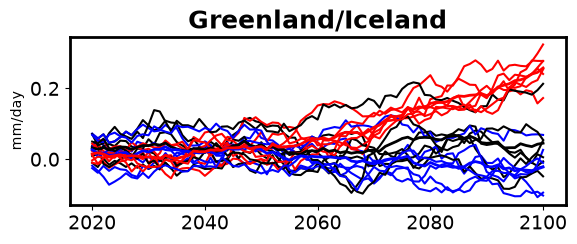

In [5]:
i = 0                       # MATLAB region index 1
time = np.arange(2020, 2101)
mvm = 10

fig = plt.figure()
ax = fig.add_subplot(2, 1, 1)
for im in range(6):
    ax.plot(time, movmean(ta_reg_sulf[im, :, i], mvm), "k")
    ax.plot(time, movmean(ta_reg_solar[im, :, i], mvm), "b")
    ax.plot(time, movmean(ta_reg_ssp[im, :, i], mvm), "r")

ax.plot(time, movmean(np.mean(ta_reg_sulf[:, :, i], axis=0), mvm), "k", linewidth=2)
ax.plot(time, movmean(np.mean(ta_reg_solar[:, :, i], axis=0), mvm), "b", linewidth=2)
ax.plot(time, movmean(np.mean(ta_reg_ssp[:, :, i], axis=0), mvm), "r", linewidth=2)

ax.set_title(regions[i].Name, fontsize=18, fontweight="bold", color="k")
ax.set_ylabel("mm/day")
for s in ax.spines.values():
    s.set_linewidth(2)
ax.tick_params(labelsize=14)
fig.set_facecolor("w")
ax.set_facecolor("w")
plt.show()

## End-of-century variances
Multi-model variance of the 2080–2100 mean response (years 61:81 in MATLAB →
`[60:81]`), using the sample standard deviation (`std(...,0)` → `ddof=1`).

In [6]:
ta_var_sulf = np.full(nR, np.nan)
ta_var_solar = np.full(nR, np.nan)
ta_var_ssp = np.full(nR, np.nan)

for i in range(nR):
    x = np.mean(ta_reg_sulf[:, 60:81, i], axis=1)
    y = np.mean(ta_reg_solar[:, 60:81, i], axis=1)
    z = np.mean(ta_reg_ssp[:, 60:81, i], axis=1)
    ta_var_sulf[i] = np.std(x, ddof=1) ** 2
    ta_var_solar[i] = np.std(y, ddof=1) ** 2
    ta_var_ssp[i] = np.std(z, ddof=1) ** 2

print("region 0 variances (sulf, solar, ssp):",
      ta_var_sulf[0], ta_var_solar[0], ta_var_ssp[0])

region 0 variances (sulf, solar, ssp): 0.004774909095013784 0.0029621138102119897 0.0012663696189830296


## Save outputs
The MATLAB script ends with `save('pr_regions1_std.mat', ...)`. This file is
*created by a script in this folder*, so per the conversion policy it is
written in the Python-native format to `data_py/pr_regions1_std.npz`
(the original `.mat` is left untouched).

In [7]:
mu.save_npz("pr_regions1_std",
            ta_var_sulf=ta_var_sulf,
            ta_var_solar=ta_var_solar,
            ta_var_ssp=ta_var_ssp)
print("saved data_py/pr_regions1_std.npz")

saved data_py/pr_regions1_std.npz
